# OpenBench Phase 6: Model Evaluation and Comparison

This notebook compares the saved TF-IDF + Logistic Regression baseline and TextCNN on the same reconstructed validation examples. It loads saved artifacts and comparison outputs; it does not train either model. Only the labeled IMDb training directory is read. The official test split and unlabeled reviews remain untouched.

Run `python -m deeptext.experiments.comparison` from the project root to create a new comparison output before opening this notebook.

## 1. Phase 6 objectives and scope

The notebook audits historical run metadata, verifies the split and saved predictions, presents unified metrics and errors, and reviews the recorded efficiency measurements, artifact sizes, and TextCNN learning curves. It does not tune models, modify checkpoints, or use validation labels as model inputs.

In [1]:
import hashlib
import json
import sys
from pathlib import Path

import matplotlib

matplotlib.use("Agg")
import numpy as np
import pandas as pd
import torch
from IPython.display import Image, display

candidate_roots = [Path.cwd().resolve(), *Path.cwd().resolve().parents]
PROJECT_ROOT = next(
    (
        path
        for path in candidate_roots
        if (path / "pyproject.toml").is_file() and (path / "src/deeptext").is_dir()
    ),
    None,
)
if PROJECT_ROOT is None:
    raise FileNotFoundError(
        "Open this notebook from the OpenBench project or one of its subfolders."
    )
if str(PROJECT_ROOT / "src") not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT / "src"))

comparison_files = list(
    (PROJECT_ROOT / "outputs" / "comparison").glob("imdb-comparison-*/comparison.json")
)
if not comparison_files:
    raise FileNotFoundError(
        "No Phase 6 comparison output found. Run the comparison module first."
    )
COMPARISON_FILE = max(comparison_files, key=lambda path: path.stat().st_mtime)
COMPARISON_DIRECTORY = COMPARISON_FILE.parent
comparison = json.loads(COMPARISON_FILE.read_text(encoding="utf-8"))
predictions = pd.read_csv(
    COMPARISON_DIRECTORY / comparison["artifacts"]["validation_predictions"]
)
baseline_directory = PROJECT_ROOT / comparison["artifacts"]["baseline_run"]
textcnn_directory = PROJECT_ROOT / comparison["artifacts"]["textcnn_run"]
DATASET_DIRECTORY = PROJECT_ROOT / "datasets" / "aclImdb"

assert comparison["official_test_evaluated"] is False
assert comparison["unlabeled_reviews_used"] is False
print(f"Comparison output: {COMPARISON_DIRECTORY.relative_to(PROJECT_ROOT)}")
print(f"Python {sys.version.split()[0]} | PyTorch {torch.__version__}")

Comparison output: outputs\comparison\imdb-comparison-20261030T124928.376528Z
Python 3.15.2 | PyTorch 2.15.0+cu132


## 2. Artifact and configuration audit

The experiment metadata records the selected models, configurations, labels, and historical results. Historical training and latency numbers are shown as such; their original timing scopes differ, so they are not treated as directly comparable.

In [2]:
baseline_metadata = json.loads(
    (baseline_directory / "metadata.json").read_text(encoding="utf-8")
)
textcnn_metadata = json.loads(
    (textcnn_directory / "metadata.json").read_text(encoding="utf-8")
)
audit_table = pd.DataFrame(
    [
        {
            "Model": "TF-IDF + Logistic Regression",
            "Training rows": baseline_metadata["split"]["training_rows"],
            "Validation rows": baseline_metadata["split"]["validation_rows"],
            "Seed": baseline_metadata["split"]["random_state"],
            "Settings": baseline_metadata["selected_settings"],
        },
        {
            "Model": "TextCNN",
            "Training rows": textcnn_metadata["split"]["training_rows"],
            "Validation rows": textcnn_metadata["split"]["validation_rows"],
            "Seed": textcnn_metadata["split"]["random_state"],
            "Settings": textcnn_metadata["model_config"],
        },
    ]
)
display(audit_table)
display(
    pd.DataFrame(
        [
            {"Result": name, "Reproduced": value}
            for name, value in comparison["historical_metric_reproduction"][
                "reproduced"
            ].items()
        ]
    )
)
print(comparison["split_audit"]["identity_evidence"])

,Model,Training rows,Validation rows,Seed,Settings
0,TF-IDF + Logistic Regression,20000,5000,42,"{'c': 1.0, 'max_iter': 1000, 'ngram_range': [1..."
1,TextCNN,20000,5000,42,"{'dropout': 0.5, 'embedding_dim': 100, 'filter..."


,Result,Reproduced
0,baseline_artifact_reload_predictions_equivalent,True
1,logistic_regression_matches_recorded_metrics,True
2,textcnn_checkpoint_reload_verified,True
3,textcnn_matches_recorded_metrics,True


Both experiment runners call load_imdb_split(dataset, 'train') followed by split_training_data with validation_size=0.2 and seed=42; this audit reconstructs that deterministic split and both saved metric sets reproduce exactly. Original artifacts do not contain row IDs or a split fingerprint.


## 3. Dataset and validation split verification

Both source runners load only `train`, then call the same stratified 80/20 split with seed 42. This cell reconstructs that split, hashes the current ordered review IDs, and verifies that each saved prediction row aligns with the reconstructed validation order. Original experiment metadata did not save sample IDs or split hashes, so the shared code path and exact metric reproduction are the available historical evidence.

In [3]:
from deeptext.data.dataset import load_imdb_split, split_training_data

all_labeled_training = load_imdb_split(DATASET_DIRECTORY, "train")
training_records, validation_records = split_training_data(
    all_labeled_training, validation_size=0.2, seed=42
)
assert len(training_records) == 20_000
assert len(validation_records) == 5_000
assert validation_records["review_id"].tolist() == predictions["review_id"].tolist()


def records_fingerprint(records):
    digest = hashlib.sha256()
    for review_id, label, text in records[["review_id", "label", "text"]].itertuples(
        index=False, name=None
    ):
        text_hash = hashlib.sha256(text.encode("utf-8")).hexdigest()
        digest.update(f"{review_id}\0{int(label)}\0{text_hash}\n".encode("utf-8"))
    return digest.hexdigest()


assert (
    records_fingerprint(validation_records)
    == comparison["split_audit"]["validation_review_fingerprint_sha256"]
)
training_texts = training_records["text"].tolist()
validation_texts = validation_records["text"].tolist()
labels = validation_records["label"].to_numpy(dtype=np.int64)
duplicate_texts = set(training_texts).intersection(validation_texts)
print(
    f"Train rows: {len(training_records):,}; "
    f"validation rows: {len(validation_records):,}"
)
print(
    f"Train/validation exact-text overlap: {len(duplicate_texts)} "
    f"unique texts across "
    f"{int(predictions['exact_text_seen_in_training'].sum())} validation rows"
)
print(f"Validation fingerprint: {records_fingerprint(validation_records)}")

Train rows: 20,000; validation rows: 5,000
Train/validation exact-text overlap: 26 unique texts across 28 validation rows
Validation fingerprint: 25a0da092c8393073a957dd2f81268fcaa404c93182728041115749c8967ff96


## 4. Load the existing baseline artifact

The baseline is the saved TF-IDF + Logistic Regression pipeline selected in Phase 3. The following spot check reproduces its classes and positive-class probabilities for the first 16 ordered validation reviews.

In [4]:
from deeptext.models.baseline import (
    load_baseline_artifacts,
    predict_baseline,
    predict_baseline_probabilities,
)

baseline_model, _ = load_baseline_artifacts(baseline_directory)
spot_count = 16
spot_baseline_predictions = predict_baseline(
    baseline_model, validation_texts[:spot_count]
)
spot_baseline_probabilities = predict_baseline_probabilities(
    baseline_model, validation_texts[:spot_count]
)[:, 1]
assert np.array_equal(
    spot_baseline_predictions,
    predictions["baseline_prediction"].to_numpy()[:spot_count],
)
assert np.allclose(
    spot_baseline_probabilities,
    predictions["baseline_positive_probability"].to_numpy()[:spot_count],
    atol=1e-12,
)
print(
    "Baseline spot-check passed. Positive probability is class 1 (positive sentiment)."
)

Baseline spot-check passed. Positive probability is class 1 (positive sentiment).


## 5. Load the existing TextCNN checkpoint and vocabulary

Load the already selected best-validation-F1 checkpoint on CPU. The stored vocabulary is paired with the checkpoint; no checkpoint selection or training occurs here.

In [5]:
from deeptext.inference import load_textcnn_predictor

torch.set_num_threads(1)
textcnn_predictor = load_textcnn_predictor(textcnn_directory, device="cpu")
assert (
    textcnn_predictor.vocabulary.size
    == textcnn_metadata["preprocessing"]["actual_vocabulary_size"]
)
assert next(textcnn_predictor.model.parameters()).device.type == "cpu"
spot_textcnn = [
    textcnn_predictor.predict(text) for text in validation_texts[:spot_count]
]
spot_textcnn_predictions = [row["predicted_class"] for row in spot_textcnn]
spot_textcnn_probabilities = [row["positive_probability"] for row in spot_textcnn]
assert (
    spot_textcnn_predictions == predictions["textcnn_prediction"].tolist()[:spot_count]
)
assert np.allclose(
    spot_textcnn_probabilities,
    predictions["textcnn_positive_probability"].to_numpy()[:spot_count],
    atol=1e-6,
)
print("TextCNN checkpoint/vocabulary spot-check passed on CPU.")

TextCNN checkpoint/vocabulary spot-check passed on CPU.


## 6. Reproduced validation predictions

The full prediction arrays were generated from the saved artifacts in deterministic validation order and saved without review text. These checks validate array lengths, labels, and prediction alignment.

In [6]:
assert len(predictions) == len(validation_records) == comparison["sample_count"]
assert predictions["true_label"].to_numpy().tolist() == labels.tolist()
assert predictions["baseline_prediction"].isin([0, 1]).all()
assert predictions["textcnn_prediction"].isin([0, 1]).all()
assert np.isfinite(predictions["baseline_positive_probability"]).all()
assert np.isfinite(predictions["textcnn_positive_probability"]).all()
print(f"Aligned {len(predictions):,} labels and predictions from the two saved models.")
print("Recorded validation metrics reproduced exactly for both artifacts.")

Aligned 5,000 labels and predictions from the two saved models.
Recorded validation metrics reproduced exactly for both artifacts.


## 7. Unified metrics comparison

Metrics use negative `0`, positive `1`, positive class `1`, confusion matrix labels `[0, 1]`, and `zero_division=0`. The table is calculated by the shared project comparison helper.

In [7]:
from deeptext.evaluation.comparison import evaluate_comparison_model

baseline_metrics = evaluate_comparison_model(
    labels,
    predictions["baseline_prediction"],
    predictions["baseline_positive_probability"],
)
textcnn_metrics = evaluate_comparison_model(
    labels,
    predictions["textcnn_prediction"],
    predictions["textcnn_positive_probability"],
)
metric_rows = []
for label, key in [
    ("TF-IDF + Logistic Regression", "baseline"),
    ("TextCNN", "textcnn"),
]:
    result = baseline_metrics if key == "baseline" else textcnn_metrics
    metric_rows.append(
        {
            "Model": label,
            "Accuracy (%)": 100 * result["accuracy"],
            "Precision (%)": 100 * result["precision"],
            "Recall (%)": 100 * result["recall"],
            "F1 (%)": 100 * result["f1"],
            "False positives": result["false_positive"],
            "False negatives": result["false_negative"],
        }
    )
comparison_table = pd.DataFrame(metric_rows).set_index("Model")
display(comparison_table.round(2))

,Accuracy (%),Precision (%),Recall (%),F1 (%),False positives,False negatives
Model,,,,,,
TF-IDF + Logistic Regression,87.72,86.64,89.2,87.90,344,270
TextCNN,84.92,81.93,89.6,85.59,494,260


## 8. Confusion matrices

Rows are actual labels and columns are predictions, ordered negative then positive.

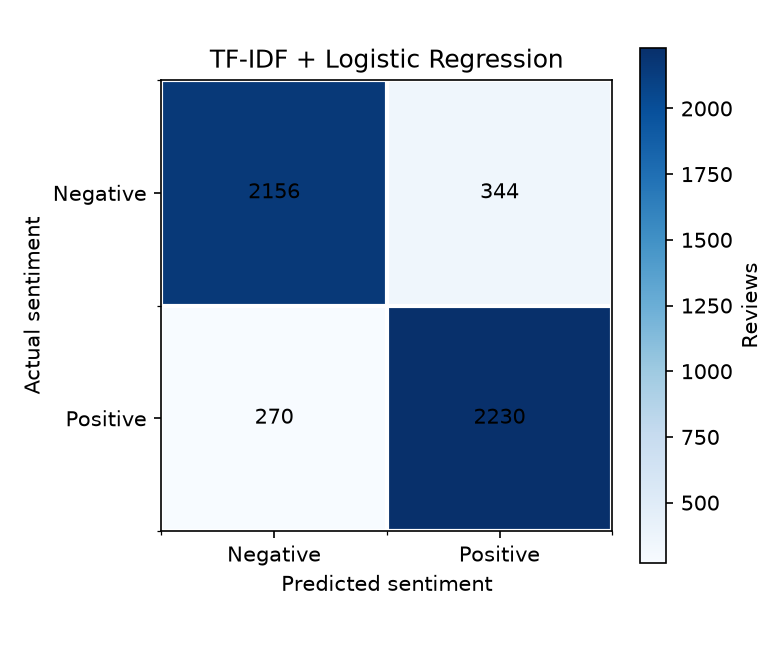

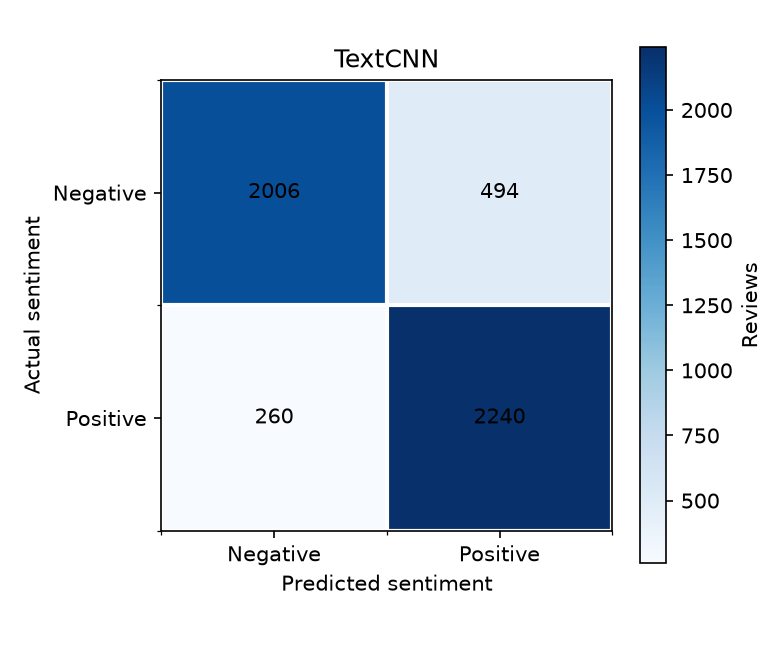

In [8]:
display(
    Image(
        filename=str(COMPARISON_DIRECTORY / "confusion_matrix_logistic_regression.png")
    )
)
display(Image(filename=str(COMPARISON_DIRECTORY / "confusion_matrix_textcnn.png")))

## 9. Error analysis

Categories count examples both correct, only one model correct, or both models wrong. In a binary task, when both are wrong they necessarily make the same incorrect class prediction. The selected snippets are exploratory examples, not evidence for a general explanation. Probabilities are each model's own outputs and are not treated as calibrated or comparable confidence scores.

In [9]:
error_counts = comparison["error_analysis"]["categories"]
display(
    pd.DataFrame(
        [
            {"Category": name.replace("_", " ").capitalize(), "Count": count}
            for name, count in error_counts.items()
        ]
    )
)
error_examples = pd.DataFrame(comparison["error_analysis"]["selected_error_examples"])
display(
    error_examples[
        [
            "text_snippet",
            "true_label",
            "baseline_prediction",
            "baseline_positive_probability",
            "textcnn_prediction",
            "textcnn_positive_probability",
            "error_category",
        ]
    ]
)
duplicate_audit = comparison["split_audit"]["duplicate_subgroup_metrics"]
display(
    pd.DataFrame(
        [
            {
                "Partition": name.replace("_", " ").capitalize(),
                "Samples": item["sample_count"],
                "LR accuracy": item["logistic_regression"]["accuracy"]
                if item["logistic_regression"]
                else None,
                "TextCNN accuracy": item["textcnn"]["accuracy"]
                if item["textcnn"]
                else None,
            }
            for name, item in duplicate_audit.items()
        ]
    )
)

,Category,Count
0,Baseline only correct,417
1,Both correct,3969
2,Both wrong same prediction,337
3,Different predictions,694
4,Textcnn only correct,277


,text_snippet,true_label,baseline_prediction,baseline_positive_probability,textcnn_prediction,textcnn_positive_probability,error_category
0,"In the questionable comedy vein of Mel Brooks,...",0,0,0.352253,1,0.821294,baseline_only_correct
1,Splendid film that in just eight minutes displ...,1,1,0.588481,0,0.449773,baseline_only_correct
2,Now I had the pleasure of first viewing Contam...,1,1,0.728222,0,0.459861,baseline_only_correct
3,A pretty memorable movie of the animals-killin...,1,1,0.691725,0,0.251133,baseline_only_correct
4,"In a variant of Sholay , Ram Gopal Verma ventu...",0,1,0.513064,0,0.375005,textcnn_only_correct
5,"Robert Culp (they call his character ""doctor""....",1,0,0.372741,0,0.215725,both_wrong_same_prediction
6,"I now that these days, some people wan't see a...",1,1,0.548410,0,0.232082,baseline_only_correct
7,Just Cause is one of those films that at first...,0,1,0.600401,1,0.857317,both_wrong_same_prediction
8,We know that firefighters and rescue workers a...,0,1,0.570004,0,0.066881,textcnn_only_correct
9,This film just goes to prove that not every fi...,0,1,0.541995,1,0.564141,both_wrong_same_prediction


,Partition,Samples,LR accuracy,TextCNN accuracy
0,Duplicate validation rows,28,1.000000,0.928571
1,Nonduplicate validation rows,4972,0.876508,0.848753


## 10. Inference latency and throughput

Latency is end-to-end from raw review through the existing preprocessing and prediction interfaces. It uses the first 100 validation reviews, five warmups, three timed passes, and mean/median over 300 review calls. Batch throughput uses the same 100 reviews, batch size 32, one warmup batch, and three timed passes. CPU runs use one PyTorch thread and a one-thread scikit-learn/BLAS limit. CUDA timings synchronize around measurements. CPU comparisons are like-for-like; CUDA results are shown for TextCNN separately.

,Median ms/review,Mean ms/review,Batch samples/s
Model/device,,,
TF-IDF + Logistic Regression (CPU),1.001,1.020,2895.116
TextCNN (CPU),2.319,1.957,834.673
TextCNN (NVIDIA GeForce RTX 3050 A Laptop GPU),2.578,2.293,3204.738


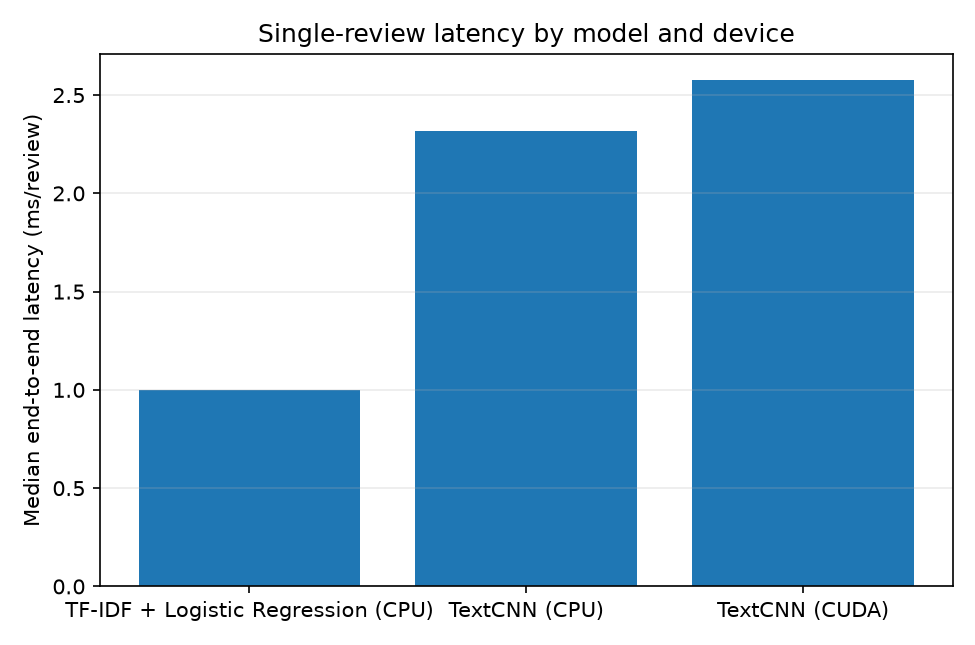

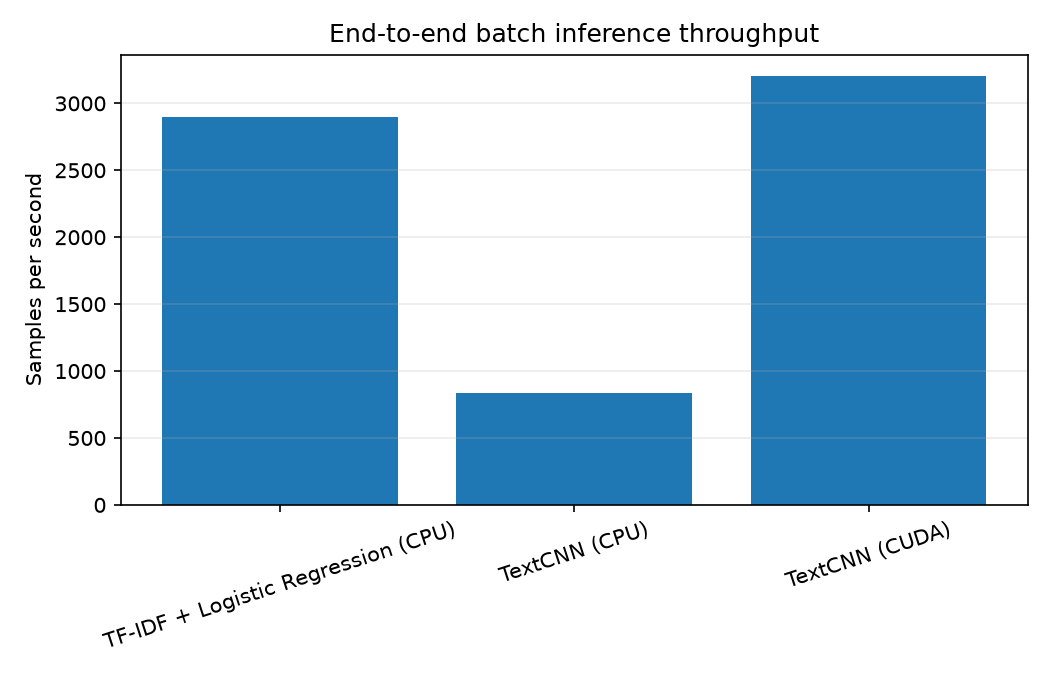

In [10]:
latency_cpu = comparison["benchmarks"]["single_review_latency_cpu"]
throughput = comparison["benchmarks"]["batch_throughput"]
benchmark_rows = []
for model_label, model_key in [
    ("TF-IDF + Logistic Regression", "logistic_regression"),
    ("TextCNN", "textcnn"),
]:
    item = latency_cpu[model_key]
    batch = comparison["benchmarks"]["batch_throughput_cpu"][model_key]
    benchmark_rows.append(
        {
            "Model/device": f"{model_label} (CPU)",
            "Median ms/review": item["median_latency_ms"],
            "Mean ms/review": item["mean_latency_ms"],
            "Batch samples/s": batch["samples_per_second"],
        }
    )
gpu_item = comparison["benchmarks"]["single_review_latency_gpu"]["textcnn"]
gpu_batch = throughput.get("textcnn_gpu")
if gpu_item is not None:
    benchmark_rows.append(
        {
            "Model/device": f"TextCNN ({gpu_item['device']})",
            "Median ms/review": gpu_item["median_latency_ms"],
            "Mean ms/review": gpu_item["mean_latency_ms"],
            "Batch samples/s": gpu_batch["samples_per_second"] if gpu_batch else None,
        }
    )
display(pd.DataFrame(benchmark_rows).set_index("Model/device").round(3))
display(Image(filename=str(COMPARISON_DIRECTORY / "inference_latency_by_device.png")))
display(Image(filename=str(COMPARISON_DIRECTORY / "batch_throughput.png")))

## 11. Artifact-size comparison

The measured boundary includes every file required by each project's existing inference loader. For Logistic Regression that is the pipeline and metadata. For TextCNN it is the weights/configuration checkpoint, vocabulary, and metadata. The TextCNN training history is excluded because inference loading does not require it.

In [11]:
artifact_sizes = comparison["artifact_sizes"]
size_rows = []
for model_name in ["logistic_regression", "textcnn"]:
    measurement = artifact_sizes[model_name]
    for file_name, byte_count in measurement["files"].items():
        size_rows.append(
            {
                "Model": model_name.replace("_", " ").title(),
                "File": file_name,
                "Bytes": byte_count,
            }
        )
    size_rows.append(
        {
            "Model": model_name.replace("_", " ").title(),
            "File": "Required total",
            "Bytes": measurement["total_bytes"],
        }
    )
display(pd.DataFrame(size_rows))
print(artifact_sizes["measurement_boundary"])

,Model,File,Bytes
0,Logistic Regression,baseline.joblib,22676878
1,Logistic Regression,metadata.json,4575
2,Logistic Regression,Required total,22681453
3,Textcnn,best_model.pt,12487542
4,Textcnn,metadata.json,2795
5,Textcnn,vocabulary.json,484155
6,Textcnn,Required total,12974492


Files required by the existing artifact loaders; excludes the separate TextCNN training history and all comparison outputs.


## 12. TextCNN learning curves

The curves below use the saved Phase 5 history only. Training/validation loss, accuracy, and F1 were recorded for all five epochs; the red vertical line marks the saved best-F1 checkpoint epoch. No curves are reconstructed from predictions.

Available saved curves: training_loss, validation_loss, training_accuracy, validation_accuracy, training_f1, validation_f1


,epoch,epoch_duration_seconds,training_accuracy,training_f1,training_loss,training_precision,training_recall,validation_accuracy,validation_f1,validation_loss,validation_precision,validation_recall
0,1,7.521560,0.76275,0.769358,0.470836,0.748510,0.7914,0.8386,0.841235,0.357107,0.827720,0.8552
1,2,8.238213,0.88630,0.886922,0.277406,0.882097,0.8918,0.8492,0.855942,0.345942,0.819312,0.8960
2,3,7.862996,0.94855,0.948655,0.142978,0.946718,0.9506,0.8546,0.853280,0.373494,0.861100,0.8456
3,4,7.888160,0.98375,0.983761,0.052735,0.983122,0.9844,0.8480,0.849743,0.479746,0.840109,0.8596
4,5,7.413268,0.99395,0.993947,0.021751,0.994395,0.9935,0.8474,0.848340,0.580945,0.843145,0.8536


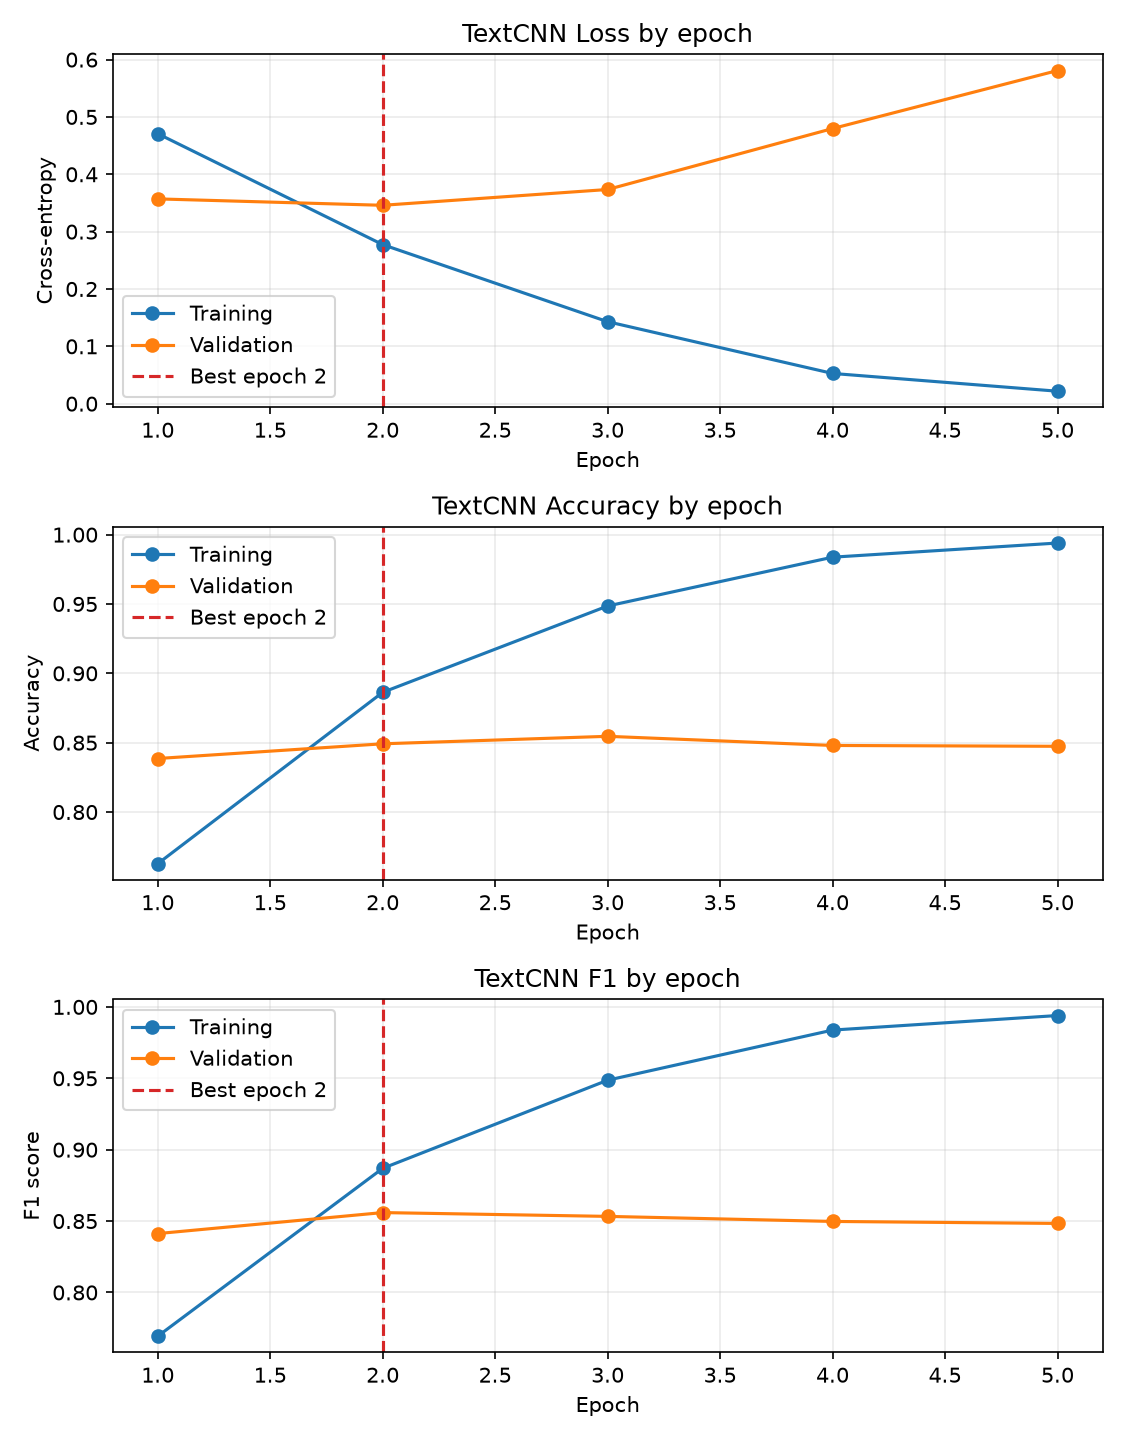

In [12]:
history_path = PROJECT_ROOT / comparison["textcnn_learning_history"]["history_file"]
history = json.loads(history_path.read_text(encoding="utf-8"))["epochs"]
history_frame = pd.DataFrame(history)
assert len(history_frame) == comparison["textcnn_learning_history"]["epoch_count"]
recorded_history_metrics = comparison["textcnn_learning_history"]["available_metrics"]
print(f"Available saved curves: {', '.join(recorded_history_metrics)}")
display(history_frame)
display(Image(filename=str(COMPARISON_DIRECTORY / "textcnn_learning_curves.png")))

## 13. Key findings

On this shared validation split, the baseline has higher accuracy, precision, and F1; TextCNN has higher recall and fewer false negatives, with more false positives. The duplicate-overlap subgroup is small (28 rows) and both models perform very well on it, so some validation scores may benefit from exact-text leakage. The comparison does not establish generalization beyond this validation data.

## 14. Limitations and conclusions

The original run metadata did not save validation review IDs or fingerprints. Both runners use the same ordered training loader and deterministic stratified split (20%, seed 42), and this reconstruction reproduces both historical metric sets exactly; the comparison uses that reconstructed common split. This is strong code-and-result evidence, but the original memberships cannot be independently fingerprinted from the old artifacts alone.

The training times are historical and have different timing boundaries, so they are not directly compared. New CPU inference measurements use identical 100-review validation samples and end-to-end boundaries. CNN probabilities and Logistic Regression probabilities are model-specific and are not assumed calibrated against each other. The official IMDb test split was not loaded or evaluated.